# Search a Trade Space

This example demonstrates how to search a trade space of constellation designs for Pareto-efficient designs with the `tatc.tradespace` module: declaring a hierarchical design space, evaluating designs in replicates (in parallel, with a cache of the analysis of each satellite), ranking them with the uncertainty of their replicates, screening them with a cheaper analysis, and searching the space with optimizers (Optuna and pymoo, installed with `pip install tatc[tradespace]`).

The trade is a sampling problem of a pre-Phase A study: how many satellites, in how many orbit planes (each of which needs its own launch), sample the Earth sufficiently often? A point is **sufficiently sampled** if an imager observes it at least four times in a day, and the objective is the share of points that are. The points are a random sample of the Earth, so the share is a statistical estimate: each replicate of a design draws a different sample of points, which is the uncertainty of the estimate.

## Configure the Scenario

The analysis covers one day, with 100 random points in each of five replicates. A design may have at most 10 satellites.

In [1]:
from datetime import datetime, time as time_of_day, timedelta, timezone
from pathlib import Path
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

START = datetime(2026, 7, 1, tzinfo=timezone.utc)
DURATION = timedelta(days=1)  # the period of the analysis
N_POINTS = 100  # random points sampled in each replicate
N_REPLICATES = 5  # replicates (samples of points) of each design
SAMPLES_PER_DAY = 4  # a point is sufficiently sampled if it is observed at least this often
MAX_SATELLITES = 10

BLUE, ORANGE, AQUA, YELLOW, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8a86", "#2b2b29"

## Define the Design Space

A `DesignSpace` declares the design variables, in the order they are decided. Every design has an altitude and an imager's field of regard, and a layout that is one of two alternatives (a `Choice`), each declared with a building block of the `tatc.tradespace` module:

* a **Walker delta** constellation (`walker_space`), with an inclination, a number of planes, a number of satellites in each plane, and the relative spacing of the satellites between planes (whose upper bound depends on the number of planes), or
* one or two **sun-synchronous** planes (`sso_planes_space`, a `Repeat` of planes), each with its own equator crossing time and number of satellites. The planes are unordered: two planes in either order are the same design. A constraint of the building block requires the planes to have different crossing times (otherwise, they would be the same plane).

The points sampled in each replicate are an `Uncertain` parameter (the seed of a random sample), drawn for each replicate rather than designed. The replicates use common random numbers: every design samples the same points in the same replicate, so that differences between designs are not differences between their samples.

The constraint on the number of satellites returns the number in excess of the limit (a number that is not positive if the design satisfies it), rather than `True` or `False`, so that optimizers can tell how far an infeasible design is from a feasible one.

In [2]:
from tatc.tradespace import (
    Categorical,
    Choice,
    DesignSpace,
    Integer,
    Real,
    Uncertain,
    count_satellites,
    sso_planes_space,
    walker_space,
)

space = DesignSpace(
    altitude=Real(500e3, 800e3, step=100e3),
    field_of_regard=Categorical([30, 60]),
    layout=Choice(
        walker=walker_space(inclination=Real(45, 75, step=15), planes=Integer(1, 4), per_plane=Integer(1, 4)),
        sso=sso_planes_space(crossing=Real(6, 18, step=3), satellites=Integer(1, 2), count=Integer(1, 2)),
    ),
    points_seed=Uncertain(lambda rng: int(rng.integers(2**31)), nominal=None),
    constraints=[lambda d: count_satellites(d.layout) - MAX_SATELLITES],
)
designs = space.enumerate()
print(f"{len(designs)} feasible designs of {len(space.unit_paths())} decisions")

1096 feasible designs of 12 decisions


## Define the Study

A `Study` builds each design into its satellites (`build`, with `build_constellation`, which builds the satellites of either layout with a payload: here, an imager, but also entries of the instrument catalog) and evaluates them (`evaluate`) in each replicate. The evaluation collects the observations of the replicate's points by each satellite, from a `SatelliteCache`: designs share many satellites (the same orbit and imager, if not the same name), whose observations are computed once. The cache is kept on disk, where the parallel worker processes of the study (`n_jobs=-1`, one per processor) share it, and where it persists between sessions. Its namespace identifies the analysis: the points, the start, and the duration.

`make_study` makes studies of other durations and numbers of replicates, as for screening (below). Each evaluation also reports its cost (`satellite_days`, the satellites times the days analyzed), which measures the computation independently of the cache.

In [3]:
from tatc.analysis import collect_observations
from tatc.generation import generate_points_random
from tatc.schemas import Instrument
from tatc.tradespace import SatelliteCache, Study, build_constellation, count_planes

CACHE_DIRECTORY = Path(tempfile.gettempdir()) / "tatc-search-trade-space"
caches = {}


def get_cache(seed, duration):
    """A cache of the observations by each satellite of the random points of a seed over a duration."""
    if (seed, duration) not in caches:
        points = generate_points_random(N_POINTS, seed=seed)
        caches[seed, duration] = SatelliteCache(
            lambda satellite: collect_observations(points, satellite, START, START + duration),
            directory=CACHE_DIRECTORY,
            namespace=f"{N_POINTS} points, seed {seed}, start {START.isoformat()}, duration {duration}",
        )
    return caches[seed, duration]


def build(d):
    """The design and its satellites."""
    imager = Instrument(name="imager", field_of_regard=d.field_of_regard)
    return d, build_constellation(d.layout, imager, epoch=START, altitude=d.altitude)


def make_study(duration=DURATION, replicates=N_REPLICATES):
    """A study of the share (%) of points sampled sufficiently over a duration."""
    threshold = SAMPLES_PER_DAY * duration / timedelta(days=1)

    def evaluate(built):
        d, members = built
        samples = get_cache(d.points_seed, duration)(members).groupby("target_hash").size()
        return {
            "satellites": len(members),
            "planes": count_planes(d.layout),
            "sufficient": 100 * (samples >= threshold).sum() / N_POINTS,
            "satellite_days": len(members) * duration / timedelta(days=1),
        }

    return Study(space, build, evaluate, replicates=replicates, n_jobs=-1)


OBJECTIVES = {"satellites": "min", "planes": "min", "sufficient": "max"}
REFERENCE = {"satellites": MAX_SATELLITES + 1, "planes": 5, "sufficient": 0}  # worse than every design, for hypervolumes

## Evaluate Every Design

The design space is small enough to evaluate every design, which gives the true Pareto front against which the screening and the searches below are compared. `summarize` gives the mean of each objective over the replicates (and its standard deviation and standard error), and `pareto_front` the designs that no other design is as good as in every objective and better than in one.

In [4]:
from tatc.tradespace import hypervolume, pareto_front, summarize

results = make_study().run(designs)
print(f"{len(results)} evaluations: {len(designs)} designs x {N_REPLICATES} replicates")

# the values of each design, and the means of its objectives over the replicates
values = results.drop_duplicates("design").set_index("design").drop(columns=["replicate", "points_seed", "seconds", "sufficient", "feasible"])
summary = summarize(results, list(OBJECTIVES), design_columns=[])
summary["pareto"] = pareto_front(summary, OBJECTIVES)
exact_hypervolume = hypervolume(summary, OBJECTIVES, REFERENCE)


def describe(d):
    """A short description of a design."""
    if d.layout == "walker":
        layout = (
            f"Walker {d['layout.walker.inclination']:.0f} deg: {d['layout.walker.planes']:.0f} x "
            f"{d['layout.walker.per_plane']:.0f} (spacing {d['layout.walker.relative_spacing']:.0f})"
        )
    else:
        planes = [
            f"{d[f'layout.sso.planes[{k}].satellites']:.0f} at {d[f'layout.sso.planes[{k}].crossing']:02.0f}:00"
            for k in range(int(d['layout.sso.planes.count']))
        ]
        layout = "SSO: " + ", ".join(planes)
    return f"{d.altitude / 1e3:.0f} km, {d.field_of_regard} deg FOR, {layout}"


summary["description"] = [describe(values.loc[key]) for key in summary.design]
front = summary[summary.pareto].sort_values(["satellites", "planes"])
front[["description", "satellites", "planes", "sufficient", "sufficient sem"]].round(1)

5480 evaluations: 1096 designs x 5 replicates


,description,satellites,planes,sufficient,sufficient sem
1048,"800 km, 60 deg FOR, SSO: 1 at 09:00",1.0,1.0,4.2,0.7
960,"800 km, 60 deg FOR, Walker 45 deg: 1 x 2 (spac...",2.0,1.0,13.8,1.0
963,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",2.0,2.0,28.6,1.1
961,"800 km, 60 deg FOR, Walker 45 deg: 1 x 3 (spac...",3.0,1.0,37.0,1.8
962,"800 km, 60 deg FOR, Walker 45 deg: 1 x 4 (spac...",4.0,1.0,66.4,2.2
1026,"800 km, 60 deg FOR, Walker 75 deg: 2 x 3 (spac...",6.0,2.0,98.0,0.5


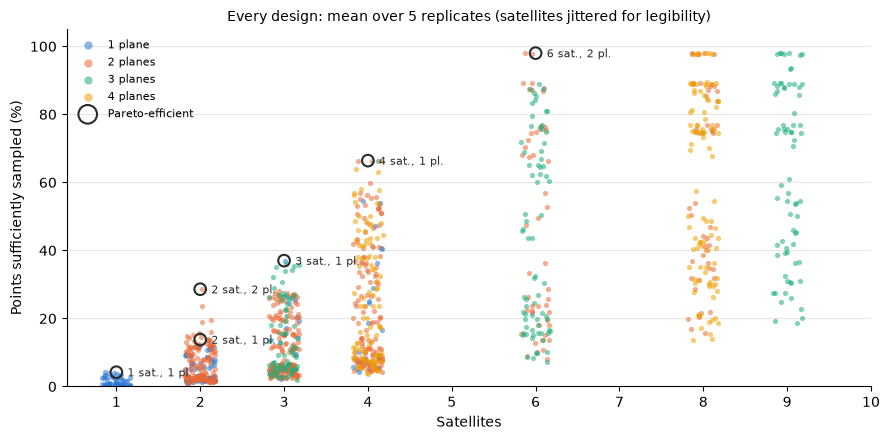

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
PLANE_COLORS = {1: BLUE, 2: ORANGE, 3: AQUA, 4: YELLOW}
jitter = np.random.default_rng(0).uniform(-0.18, 0.18, len(summary))
for planes, color in PLANE_COLORS.items():
    selected = summary.planes == planes
    ax.scatter(
        summary.satellites[selected] + jitter[selected],
        summary.sufficient[selected],
        s=14,
        color=color,
        alpha=0.55,
        lw=0,
        label=f"{planes} plane{'s' if planes > 1 else ''}",
    )
# the efficient designs, ringed and labeled
ax.scatter(front.satellites, front.sufficient, s=70, facecolor="none", edgecolor=INK, lw=1.5, label="Pareto-efficient")
for _, row in front.iterrows():
    ax.annotate(
        f"{row.satellites:.0f} sat., {row.planes:.0f} pl.",
        (row.satellites, row.sufficient),
        xytext=(8, -3),
        textcoords="offset points",
        fontsize=8,
        color=INK,
    )
ax.set(
    xlabel="Satellites",
    ylabel="Points sufficiently sampled (%)",
    xticks=range(1, MAX_SATELLITES + 1),
    ylim=(0, 105),
)
ax.grid(axis="y", color="#e6e6e3", lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(loc="upper left", fontsize=8, frameon=False, markerscale=1.6)
ax.set_title("Every design: mean over 5 replicates (satellites jittered for legibility)", fontsize=10)
fig.tight_layout()
plt.show()

Of the 1,096 feasible designs, six are Pareto-efficient (ringed in the figure). All of them fly at the highest altitude (800 km) with the wider field of regard (60 degrees), which observe the most points per satellite, so the trade is in the number of satellites and planes. One satellite samples only 4% of the points sufficiently (at least four times a day), and the share rises steeply with the number of satellites: two satellites in two planes (29%) sample twice as many points as two in one plane (14%), and six satellites in two inclined planes sample 98%. No design with more than six satellites is efficient, because six already sample nearly every point. Designs with the same number of satellites differ widely: their layout (inclination, planes, and phasing) matters as much as their number.

## Rank Designs with the Uncertainty of Replicates

The means of five replicates are uncertain, and so is the front of the means: a design just behind another in the means may be ahead of it in other samples of points. `pareto_probability` estimates the probability that each design is efficient by a bootstrap: it resamples the replicates (the same replicates for every design, which keeps the correlation between designs of common random numbers) and counts how often each design is on the front of the resampled means.

In [6]:
from tatc.tradespace import pareto_probability

probability = pareto_probability(results, OBJECTIVES, n_resamples=1000)
probability["description"] = [describe(values.loc[key]) for key in probability.design]
candidates = probability[probability.pareto_probability >= 0.1].sort_values(["satellites", "planes", "sufficient"])
candidates[["description", "satellites", "planes", "sufficient", "pareto", "pareto_probability"]].round(2)

,description,satellites,planes,sufficient,pareto,pareto_probability
1052,"800 km, 60 deg FOR, SSO: 1 at 15:00",1.0,1.0,4.0,False,0.25
1054,"800 km, 60 deg FOR, SSO: 1 at 18:00",1.0,1.0,4.0,False,0.42
1048,"800 km, 60 deg FOR, SSO: 1 at 09:00",1.0,1.0,4.2,True,0.74
1051,"800 km, 60 deg FOR, SSO: 2 at 12:00",2.0,1.0,12.2,False,0.22
960,"800 km, 60 deg FOR, Walker 45 deg: 1 x 2 (spac...",2.0,1.0,13.8,True,0.78
963,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",2.0,2.0,28.6,True,1.00
961,"800 km, 60 deg FOR, Walker 45 deg: 1 x 3 (spac...",3.0,1.0,37.0,True,1.00
1001,"800 km, 60 deg FOR, Walker 60 deg: 3 x 1 (spac...",3.0,3.0,35.4,False,0.29
698,"700 km, 60 deg FOR, Walker 45 deg: 3 x 1 (spac...",3.0,3.0,35.8,False,0.28
962,"800 km, 60 deg FOR, Walker 45 deg: 1 x 4 (spac...",4.0,1.0,66.4,True,1.00


Four of the six efficient designs are efficient in every resample: two satellites in two planes, three or four satellites in one plane, and six in two planes. The others are not settled by five replicates. One satellite in a sun-synchronous orbit crossing the equator at 09:00 (efficient in 74% of the resamples) samples about as many points as one crossing at 15:00 or 18:00 (25% and 42%), and six satellites in two planes with another relative spacing (32%) sample about as many as the efficient design. Designs that are efficient with a probability between 0 and 1 are equally good candidates, given the uncertainty of the estimates: more replicates (samples of points) would separate them, or a tolerance of the share (see `pareto_front`) would treat them as ties.

## Refine Uncertain Designs

Five replicates settle the efficiency of most designs, but not of all. More replicates of every design would settle them, at the cost of evaluating every design again for each. `refine` instead adds replicates only to the designs whose efficiency is uncertain (efficient in more than 5% and fewer than 95% of the resamples), five at a time, and estimates their probabilities again, until none is uncertain (or a design has 40 replicates). The added replicates are the next ones after each design's own, which keeps common random numbers between the designs refined together.

Some designs differ by less than any number of replicates could separate, such as those that sample nearly every point: a difference of a tenth of a percentage point does not matter to the trade. A tolerance of 1 percentage point of the share treats designs within it of the front as efficient (see `pareto_front`), so that refinement does not spend replicates on differences that do not matter.

In [7]:
from tatc.tradespace import refine

TOLERANCE = {"sufficient": 1.0}  # percentage points of the share that do not matter
refinement = refine(
    make_study(), designs, results, OBJECTIVES, step=5, max_replicates=40, n_resamples=1000, tolerance=TOLERANCE
)
added = len(refinement.results) - len(results)
print(f"{added} evaluations added, {added / (len(designs) * 35):.1%} of those of 40 replicates of every design")
refinement.history

655 evaluations added, 1.7% of those of 40 replicates of every design


,round,uncertain,refined,evaluations
0,0,20,20,100
1,1,21,21,105
2,2,18,18,90
3,3,17,17,85
4,4,15,15,75
5,5,14,14,70
6,6,15,15,75
7,7,13,6,30
8,8,12,3,15
9,9,12,2,10


In [8]:
refined = refinement.probability
refined["description"] = [describe(values.loc[key]) for key in refined.design]
refined[refined.pareto_probability >= 0.1].sort_values(["satellites", "planes", "sufficient"])[
    ["description", "satellites", "planes", "sufficient", "replicates", "pareto", "pareto_probability"]
].round(2)

,description,satellites,planes,sufficient,replicates,pareto,pareto_probability
772,"700 km, 60 deg FOR, SSO: 1 at 06:00",1.0,1.0,2.68,40,False,0.16
774,"700 km, 60 deg FOR, SSO: 1 at 09:00",1.0,1.0,2.70,40,False,0.19
778,"700 km, 60 deg FOR, SSO: 1 at 15:00",1.0,1.0,2.70,40,False,0.18
780,"700 km, 60 deg FOR, SSO: 1 at 18:00",1.0,1.0,2.72,40,False,0.19
1017,"800 km, 60 deg FOR, Walker 75 deg: 1 x 1 (spac...",1.0,1.0,3.12,40,False,0.45
1046,"800 km, 60 deg FOR, SSO: 1 at 06:00",1.0,1.0,3.40,40,True,0.63
1050,"800 km, 60 deg FOR, SSO: 1 at 12:00",1.0,1.0,3.40,40,True,0.64
1054,"800 km, 60 deg FOR, SSO: 1 at 18:00",1.0,1.0,3.42,40,True,0.65
1052,"800 km, 60 deg FOR, SSO: 1 at 15:00",1.0,1.0,4.00,5,True,0.99
1048,"800 km, 60 deg FOR, SSO: 1 at 09:00",1.0,1.0,4.20,5,True,0.99


Refinement adds 655 evaluations, 1.7% of those that 40 replicates of every design would take, to the few designs whose efficiency is uncertain. With the tolerance, the designs that sample nearly every point (six to nine satellites, about 98%) are all efficient candidates, with probabilities of 0.92 or more, rather than uncertain: they differ by less than matters. The designs that stay uncertain after ten rounds lie about one tolerance below the front, such as single satellites that sample about 3.4% of the points against the best single satellite's 4.2%: whether they are within the tolerance of the front is a question that more replicates settle only slowly, and one that does not change the trade. An absolute tolerance suits a share near saturation better than one near zero; a tolerance proportional to the objective would treat both alike.

## Require Reliable Sampling

A mean share of points sufficiently sampled does not say how reliably a design achieves it: the share differs between samples of points. Statistics over the replicates other than the mean state how a design is judged, and requirements on them are output constraints. Here, the objective is the share that a design exceeds in 80% of the samples (its 0.2 quantile, `Quantile`), and a design is required to sample at least half of the points sufficiently in at least 80% of the samples (the probability of meeting a threshold, `Probability`, with a `Requirement`). `aggregate` gives the statistics and the violations of the requirements, and `pareto_probability` the probability that each design is efficient among those that meet them.

In [9]:
from tatc.tradespace import Probability, Quantile, Requirement, aggregate

STATISTICS = {
    "sufficient p20": Quantile("sufficient", 0.2),
    "reliability": Probability("sufficient", ">=", 50),
}
RELIABLE_OBJECTIVES = {"satellites": "min", "planes": "min", "sufficient p20": "max"}
REQUIREMENTS = [Requirement("reliability", ">=", 0.8)]

reliable = pareto_probability(
    refinement.results, RELIABLE_OBJECTIVES, n_resamples=1000, statistics=STATISTICS, requirements=REQUIREMENTS
)
reliable["description"] = [describe(values.loc[key]) for key in reliable.design]
print(f"{reliable.meets_requirements.sum()} of {len(reliable)} designs meet the requirement")
reliable[reliable.pareto_probability >= 0.1].sort_values(["satellites", "planes"])[
    ["description", "satellites", "planes", "sufficient p20", "reliability", "replicates", "pareto_probability", "requirements_probability"]
].round(2)

194 of 1096 designs meet the requirement


,description,satellites,planes,sufficient p20,reliability,replicates,pareto_probability,requirements_probability
962,"800 km, 60 deg FOR, Walker 45 deg: 1 x 4 (spac...",4.0,1.0,61.8,1.0,5,1.00,1.0
965,"800 km, 60 deg FOR, Walker 45 deg: 2 x 2 (spac...",4.0,2.0,61.8,1.0,5,0.24,1.0
966,"800 km, 60 deg FOR, Walker 45 deg: 2 x 2 (spac...",4.0,2.0,62.4,1.0,5,0.38,1.0
980,"800 km, 60 deg FOR, Walker 45 deg: 4 x 1 (spac...",4.0,4.0,63.8,1.0,40,0.45,1.0
1025,"800 km, 60 deg FOR, Walker 75 deg: 2 x 3 (spac...",6.0,2.0,97.4,1.0,5,0.47,1.0
1026,"800 km, 60 deg FOR, Walker 75 deg: 2 x 3 (spac...",6.0,2.0,97.6,1.0,5,1.00,1.0
487,"600 km, 60 deg FOR, Walker 75 deg: 3 x 3 (spac...",9.0,3.0,96.8,1.0,35,0.12,1.0
762,"700 km, 60 deg FOR, Walker 75 deg: 3 x 3 (spac...",9.0,3.0,96.8,1.0,25,0.12,1.0
763,"700 km, 60 deg FOR, Walker 75 deg: 3 x 3 (spac...",9.0,3.0,96.8,1.0,25,0.11,1.0


194 of the 1,096 designs meet the requirement of sampling half of the points sufficiently in at least 80% of the samples, and none of them has fewer than four satellites: the best three satellites sample 37% of the points on average. Among those that meet it, four satellites in one plane (inclined 45 degrees) are efficient for sure, sampling at least 62% of the points in 80% of the samples, and so are six satellites in two planes inclined 75 degrees (at least 97%). Four satellites in two or four planes are nearly as good, with probabilities of 0.24 to 0.45, which are the alternatives to weigh with other criteria, such as the cost of launching more planes.

## Screen Designs with a Cheaper Analysis

Evaluating every design is affordable here, but not for larger spaces or longer analyses. `screen` evaluates every design with a cheap study, keeps the best (whole fronts, until it keeps at least `keep` of them), and evaluates only those with the full study. A cheap study ranks designs less exactly, so a `tolerance` of an objective keeps designs that are within it of the front of the cheap study.

The cheap study must rank designs as the full study would. Here, the screening study analyzes one replicate, rather than five, over a shorter period, with the threshold of sufficient sampling scaled to the period: 12 hours with two observations, or 6 hours with one. The table compares each screening's front with the true front (how many of its efficient designs it keeps, and its hypervolume), and its cost with that of evaluating every design.

In [10]:
from tatc.tradespace import screen

full_cost = results.satellite_days.sum()
true_front = set(summary.design[summary.pareto])
screenings = []
for hours, keep, tolerance in [(12, 0.05, None), (12, 0.1, 5.0), (6, 0.05, None), (6, 0.2, None)]:
    screening = screen(
        designs,
        [make_study(timedelta(hours=hours), replicates=1), make_study()],
        OBJECTIVES,
        keep=keep,
        tolerance=None if tolerance is None else {"sufficient": tolerance},
    )
    screenings.append(
        {
            "screening study": f"{hours} h, 1 replicate",
            "keep (%)": 100 * keep,
            "tolerance (%)": tolerance,
            "designs kept": len(screening.designs),
            "efficient designs kept": f"{len(true_front & {d.key for d in screening.designs})} of {len(true_front)}",
            "hypervolume (% of true front)": 100 * hypervolume(screening.final, OBJECTIVES, REFERENCE) / exact_hypervolume,
            "cost (% of every design)": 100 * screening.results.satellite_days.sum() / full_cost,
        }
    )
pd.DataFrame(screenings).round(1)

,screening study,keep (%),tolerance (%),designs kept,efficient designs kept,hypervolume (% of true front),cost (% of every design)
0,"12 h, 1 replicate",5.0,NaN,68,5 of 6,100.0,16.0
1,"12 h, 1 replicate",10.0,5.0,212,6 of 6,100.0,23.7
2,"6 h, 1 replicate",5.0,NaN,55,1 of 6,79.0,10.2
3,"6 h, 1 replicate",20.0,NaN,241,6 of 6,100.0,24.8


The 12-hour screening study ranks designs nearly as the full study does. Keeping the best 5% of the designs finds a front with the hypervolume of the true front at 16% of the cost of evaluating every design, although it misses one efficient design, whose place a design with nearly the same objectives takes. Keeping 10%, with a tolerance of 5 percentage points, keeps every efficient design at 24% of the cost.

The 6-hour screening study is cheaper, but ranks designs differently: one observation of a point in 6 hours separates designs less than four observations in a day do. Keeping 5% of the designs keeps only one of the six efficient ones (79% of the hypervolume), and it must keep 20% to keep them all, which costs as much as the 12-hour study. How many designs to keep depends on how well the cheap study ranks designs, which is worth checking on a sample of designs evaluated with both studies before screening a larger space.

## Search with Optimizers

Larger design spaces cannot be enumerated or even screened, and an optimizer searches them for efficient designs instead. `optimize_optuna` suggests designs with Optuna's trials, which search the hierarchical design space directly (`DesignSpace.suggest`), and records the violation of the constraint of each infeasible design, which Optuna's samplers use to prefer feasible designs. `optimize_pymoo` searches the unit hypercube that encodes the design space (`DesignSpace.decode`) with a pymoo algorithm. Both evaluate each design once, however often it is proposed, and evaluate the designs proposed together in parallel.

Each search below is given a budget of about 200 proposals, and is compared with a Latin hypercube sample of 200 designs (`DesignSpace.sample`). The designs evaluated (and the analyses of their satellites) are those of the evaluation of every design above, so they are retrieved from the cache.

In [11]:
import optuna
from pymoo.algorithms.moo.nsga2 import NSGA2

from tatc.tradespace import optimize_optuna, optimize_pymoo

optuna.logging.set_verbosity(optuna.logging.WARNING)
BUDGET = 200
study = make_study()
searches = {}
_, searches["Optuna (NSGA-II)"] = optimize_optuna(
    study,
    OBJECTIVES,
    n_trials=BUDGET,
    sampler=optuna.samplers.NSGAIISampler(population_size=20, seed=1),
    batch_size=20,
)
_, searches["pymoo (NSGA-II)"] = optimize_pymoo(study, OBJECTIVES, NSGA2(pop_size=20), ("n_gen", BUDGET // 20), seed=1)
searches["Latin hypercube sample"] = study.run(space.sample(BUDGET, method="lhs", seed=1))


def get_progress(search_results):
    """The hypervolume (% of the true front's) of the designs evaluated, as designs are evaluated."""
    means = summarize(search_results, list(OBJECTIVES), design_columns=[]).set_index("design")
    order = search_results.design.drop_duplicates()
    counts = np.arange(10, len(order) + 1, 10)
    return pd.Series(
        [100 * hypervolume(means.reindex(order[:n]).dropna(), OBJECTIVES, REFERENCE) / exact_hypervolume for n in counts],
        index=counts,
    )


progress = {name: get_progress(search_results) for name, search_results in searches.items()}
pd.DataFrame(
    {
        name: {
            "designs evaluated": search_results.design.nunique(),
            "hypervolume (% of true front)": progress[name].iloc[-1],
        }
        for name, search_results in searches.items()
    }
).T.round(1)

,designs evaluated,hypervolume (% of true front)
Optuna (NSGA-II),140.0,95.3
pymoo (NSGA-II),87.0,89.6
Latin hypercube sample,176.0,80.3


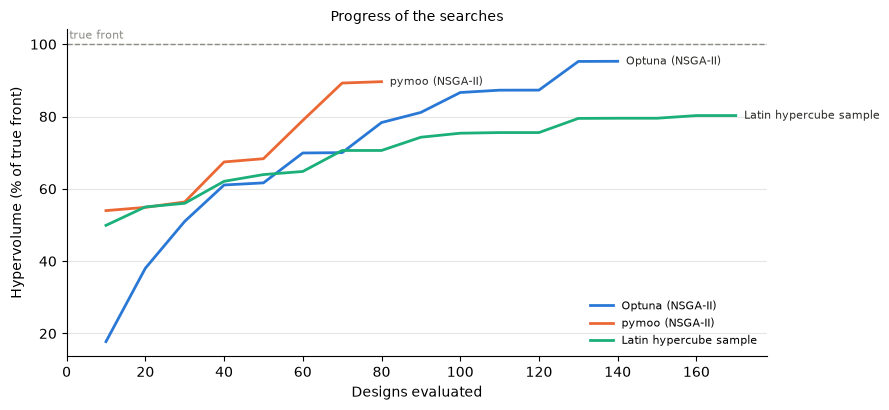

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for (name, series), color in zip(progress.items(), (BLUE, ORANGE, AQUA)):
    ax.plot(series.index, series.values, color=color, lw=2, label=name)
    ax.annotate(name, (series.index[-1], series.values[-1]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color=INK)
ax.axhline(100, color=GRAY, lw=1, ls="--")
ax.annotate("true front", (0, 100), xytext=(2, 4), textcoords="offset points", fontsize=8, color=GRAY)
ax.set(xlabel="Designs evaluated", ylabel="Hypervolume (% of true front)", xlim=(0, None))
ax.grid(axis="y", color="#e6e6e3", lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(loc="lower right", fontsize=8, frameon=False)
ax.set_title("Progress of the searches", fontsize=10)
fig.tight_layout()
plt.show()

Both optimizers find more of the hypervolume than a Latin hypercube sample of as many designs. Optuna (NSGA-II, searching the hierarchical space directly) finds 95% of the hypervolume of the true front with 140 designs, 13% of the space. pymoo (NSGA-II, searching the encoded space) finds 90% with 87 designs: its 200 proposals include many that encode the same design or that violate the constraints, which are not evaluated. The sample finds 80% with 176 designs. The searches stop at their budget of proposals, not at convergence: a larger budget, or screening, would bring them closer to the true front. Their results also depend on their seeds, so compare several seeds before relying on one.

## Summary

* A `DesignSpace` declares a hierarchical trade space, with choices between alternatives (`Choice`), repeated elements such as orbit planes (`Repeat`), bounds that depend on other variables, constraints that measure their violation, and uncertain parameters (`Uncertain`) drawn for each replicate. Building blocks declare common constellation layouts (`walker_space` and `sso_planes_space`) and build their satellites with instruments or entries of the instrument catalog (`build_constellation`).
* A `Study` evaluates designs in replicates, in parallel, with a `SatelliteCache` that analyzes each distinct satellite once. Every design of a space of about a thousand designs can be evaluated in minutes.
* The front of the means of the replicates is uncertain: `pareto_probability` finds the designs whose efficiency the replicates settle, and those that are equally good candidates, and `refine` adds replicates only to the latter, with a tolerance of differences that do not matter.
* Statistics other than means (such as a `Quantile` or the `Probability` of meeting a threshold) state how reliably a design performs, and `Requirement`s on them are output constraints.
* `screen` evaluates every design with a cheap study and the best with the full one, which finds the front at a fraction of the cost if the cheap study ranks designs as the full one does.
* `optimize_optuna` and `optimize_pymoo` search spaces too large to enumerate, and find most of the front with a fraction of the designs.

The objectives here are geometric: the share of points observed at least four times a day, and the numbers of satellites and planes as proxies of cost. The uncertainty is that of the sample of points; other uncertainties (such as the phase of the satellites or the period of the analysis) are further `Uncertain` parameters of the design space.